In [15]:
%load_ext autoreload
%autoreload 2
import sys 
sys.path.append('../')
import os
import torch
import torch.distributions as dist
import torch.nn as nn
from typing import List
from tqdm import tqdm
from torch.utils.tensorboard import SummaryWriter
from utils import load_mnist_dataset, flatten_image, unflatten_image, view_image
from unet import get_timestep_embedding, UNet
from simple_bridge import SimpleBrownianBridgeDiffusion
from mnist_denoising_diffusion_model_implementation import DiffusionModel
from collections import OrderedDict

import matplotlib.pyplot as plt
import numpy as np

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [161]:
def view_images(images, n_steps):
    """
    Function to view a sequence of images in one column.
    :param images: List of images
    :param n_steps: List of steps corresponding to each image
    :return: None
    """
    n = len(images)
    fig, axes = plt.subplots(n, 1, figsize=(5, 5 * n))
    
    if n == 1:
        axes = [axes]
    
    for i, (image, step) in enumerate(zip(images, n_steps)):
        ax = axes[i]
        ax.imshow(image.squeeze(), cmap='gray')
        ax.set_title(f'Step: {step}')
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

def view_images_two_models(images1, images2, n_steps):
    """
    Function to view a sequence of images from two models in two columns.
    :param images1: List of images from the first model
    :param images2: List of images from the second model
    :param n_steps: List of steps corresponding to each image
    :return: None
    """
    n = len(images1)
    fig, axes = plt.subplots(n, 2, figsize=(10, 5 * n))
    
    for i, step in enumerate(n_steps):
        ax1, ax2 = axes[i]
        
        ax1.imshow(images1[i].squeeze(), cmap='gray')
        ax1.set_title(f'Model 1 - Step: {step}')
        ax1.axis('off')
        
        ax2.imshow(images2[i].squeeze(), cmap='gray')
        ax2.set_title(f'Model 2 - Step: {step}')
        ax2.axis('off')
    
    plt.tight_layout()
    plt.show()

def view_images_multiple_models(images_list, n_steps, model_names):
    """
    Function to view a sequence of images from multiple models in columns.
    :param images_list: List of lists of images from each model
    :param n_steps: List of steps corresponding to each image
    :param model_names: List of model names
    :return: None
    """
    n = len(n_steps)
    num_models = len(images_list)
    fig, axes = plt.subplots(n, num_models, figsize=(5 * num_models, 5 * n))
    
    for i, step in enumerate(n_steps):
        for j in range(num_models):
            ax = axes[i, j] if num_models > 1 else axes[i]
            ax.imshow(images_list[j][i].squeeze(), cmap='gray')
            ax.set_title(f'{model_names[j]} - Step: {step}')
            ax.axis('off')
    
    plt.tight_layout()
    plt.show()

In [2]:
trainY, testY = load_mnist_dataset(root='/workspace/aim-bridges-data/mnist', download=False)

In [3]:
def remove_module_prefix(state_dict):
    """Remove 'module.' prefix from state_dict keys.
    it gets added when using DataParallel"""
    new_state_dict = OrderedDict()
    for k, v in state_dict.items():
        if k.startswith('module.'):
            new_state_dict[k[7:]] = v  # Remove 'module.' prefix
        else:
            new_state_dict[k] = v
    return new_state_dict

In [155]:
model = UNet()
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_500.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_500.pth'


<All keys matched successfully>

In [134]:
# Use DataParallel to wrap the model for multi-GPU training
#if torch.cuda.device_count() > 1:
#    print(f"Using {torch.cuda.device_count()} GPUs for sampling")
#    model = nn.DataParallel(model)

  0%|          | 0/100 [00:00<?, ?it/s]/workspace/generative-bridges/jupyter/../simple_bridge.py:77: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t, device=self.device)
100%|██████████| 100/100 [00:01<00:00, 63.10it/s]


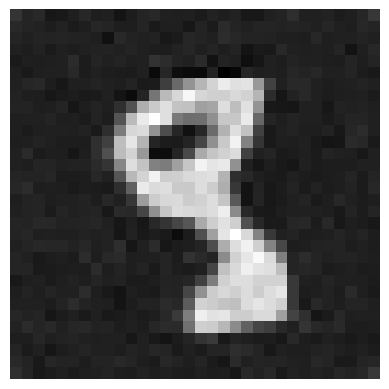

In [157]:
T = 0.1
diffusion_model = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)
samples = diffusion_model.sampling(n_samples=1, use_tqdm=True, n_steps=100)
view_image(samples.cpu()[0])

In [158]:
model_denoise = UNet()
checkpoint_path = '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_500.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model_denoise.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_500.pth'


<All keys matched successfully>

100%|██████████| 100/100 [00:01<00:00, 59.14it/s]


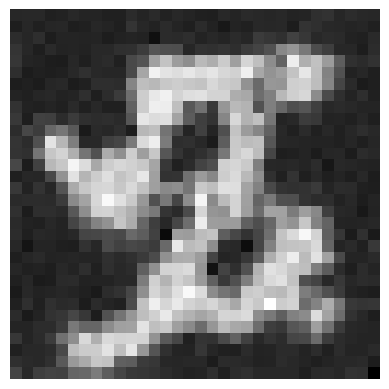

In [159]:
T = 100
diffusion_model_denoise = DiffusionModel(T, model_denoise, 'cuda', trainY)
samples = diffusion_model_denoise.sampling(n_samples=1, use_tqdm=True)
view_image(samples.cpu()[0])

In [ ]:
# Generate and visualize samples at different steps for both models
n_samples = 1
n_steps_list = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

# Samples for the first model
samples_model1 = []
for n_steps in n_steps_list:
    sample = diffusion_model.sampling(n_samples=n_samples, use_tqdm=False, n_steps=n_steps)
    samples_model1.append(sample.cpu()[0])

# Samples for the second model
samples_model2 = []
for n_steps in n_steps_list:
    diffusion_model_denoise = DiffusionModel(n_steps, model_denoise, 'cuda', trainY)
    sample = diffusion_model_denoise.sampling(n_samples=n_samples, use_tqdm=False)
    samples_model2.append(sample.cpu()[0])

# Visualize the samples
view_images_two_models(samples_model1, samples_model2, n_steps_list)

In [162]:
# bridge models
model = UNet()
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_500.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

T = 0.1
bridge_500 = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)

model = UNet()
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_2000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

T = 0.1
bridge_2000 = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)

model = UNet()
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_8000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

T = 0.1
bridge_8000 = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)

# denoising models
denoise_500 = UNet()
checkpoint_path = '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_500.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
denoise_500.load_state_dict(remove_module_prefix(checkpoint))

denoise_2000 = UNet()
checkpoint_path = '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_2000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
denoise_2000.load_state_dict(remove_module_prefix(checkpoint))

denoise_8000 = UNet()
checkpoint_path = '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_8000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
denoise_8000.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_500.pth'
Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_2000.pth'
Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_8000.pth'
Loading checkpoint '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_500.pth'
Loading checkpoint '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_2000.pth'
Loading checkpoint '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_8000.pth'


<All keys matched successfully>

In [164]:
# Generate and visualize samples at different steps for multiple models
n_samples = 1
n_steps_list = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]
model_names = ['Bridge; T=0.1; Steps=500, batch=128', 'Denoising; Steps=500, batch=128', 'Bridge; T=0.1; Steps=2000, batch=128', 'Denoising; Steps=2000, batch=128', 'Bridge; T=0.1; Steps=8000, batch=128', 'Denoising; Steps=8000, batch=128']
# List of models
models = [bridge_500, denoise_500, bridge_2000, denoise_2000, bridge_8000, denoise_8000 ]

# Function to generate samples for a given model
def generate_samples(_model, n_samples, n_steps_list, name):
    samples = []
    for n_steps in n_steps_list:
        if 'Denoising' in name:
            _model_denoise = DiffusionModel(n_steps, _model, 'cuda', trainY)
            sample = _model_denoise.sampling(n_samples=n_samples, use_tqdm=False)
        else:
            sample = _model.sampling(n_samples=n_samples, use_tqdm=False, n_steps=n_steps)
        samples.append(sample.cpu()[0])
    return samples

# Generate samples for all models
samples_list = [generate_samples(model, n_samples, n_steps_list, name) for model, name in zip(models, model_names)]

# Visualize the samples
view_images_multiple_models(samples_list, n_steps_list, model_names)

/workspace/generative-bridges/jupyter/../simple_bridge.py:77: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t, device=self.device)
